# Модель отвечает: маленький сервис внутри ноутбука

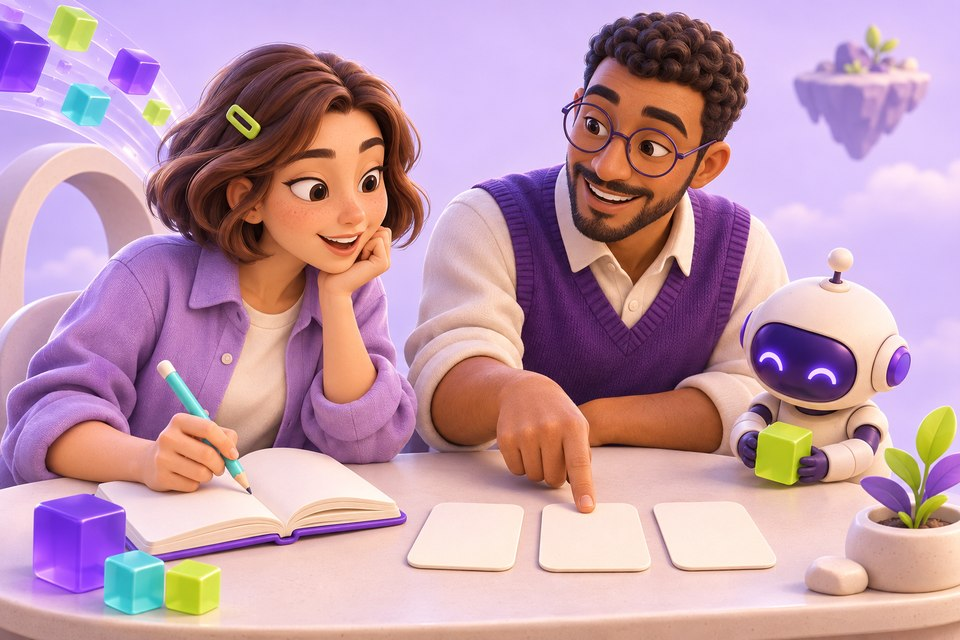

**Пропустим JSON-запрос через настоящий интерфейс WSGI без публикации.**

**Твой результат:** Получить ответ сервиса и проверить ошибки запроса вместе с единым форматом пикселей.

**Что разбираем:** Локальное упражнение WSGI с классификацией двух синтетических шаблонов по расстоянию. MNIST, TensorFlow, Streamlit и развёртывание Heroku остаются в архиве; серверный порт не открывается.

**Данные:** Два нарисованных массива 8×8: условные символы 0 и 1. Это не MNIST и не данные пользователя.

**Перед началом:**

- Запускать ячейки сверху вниз
- Менять только небольшую часть примера за раз

**Рядом с тобой:** Мира — ученица, Данил — человек-ментор, Пикс — бот-помощник. Это вымышленные персонажи: их реплики объясняют шаги и не проверяют код автоматически.

## Три шага

1. [Договоримся о пикселях один раз](#step-1)
2. [Сделаем JSON-ответ по правилам WSGI](#step-2)
3. [Проверим успешный ответ и отказы](#step-3)

[Твой эксперимент](#your-experiment)

## Подготовь рабочее место

Запускай код сверху вниз: сначала эту подготовку, затем три шага. Проверки `assert` останавливают выполнение, если результат не совпал с условием.

Библиотеки для урока: **numpy**.

In [1]:
import io
import json
import numpy as np
from wsgiref.util import setup_testing_defaults


<a id="step-1"></a>

## 1. Договоримся о пикселях один раз

На вход принимаем целые числа 0–255 размером 8×8. Одна функция готовит и эталоны, и будущий запрос; так масштаб не разъедется.

In [2]:
def prepare(raw):
    array = np.asarray(raw)
    if array.shape != (8, 8) or not np.issubdtype(array.dtype, np.integer):
        raise ValueError('Нужны 8×8 целых пикселей')
    if np.any(array < 0) or np.any(array > 255):
        raise ValueError('Яркость должна быть от 0 до 255')
    return array.astype(np.float32)/255.0
zero = np.zeros((8, 8), dtype=np.uint8)
zero[1:7, 1:7] = 255
zero[2:6, 2:6] = 0
one = np.zeros((8, 8), dtype=np.uint8)
one[1:7, 3:5] = 255
references = np.stack([prepare(zero), prepare(one)])
assert np.array_equal(prepare(one.tolist()), references[1])
assert references.min() == 0 and references.max() == 1
print('Два синтетических эталона готовы. Обучения нейросети здесь нет.')


Два синтетических эталона готовы. Обучения нейросети здесь нет.


**Что проверить:** Одинаковая подготовка списка JSON и массива эталона.

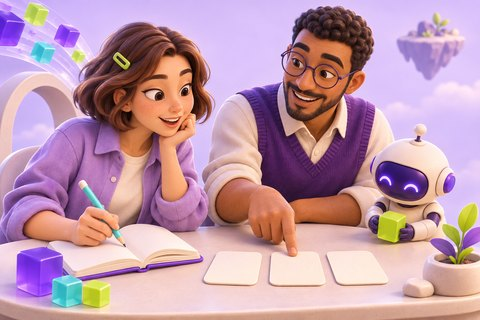

> **Мира:** Почему это важно для сервиса?

> **Данил:** Если обучающая часть видела 0–255, а сервис отправляет 0–1, это уже другой вход. Мы используем единую функцию.

> **Пикс:** Сравнение проходит по всем пикселям, а не только по форме.

<a id="step-2"></a>

## 2. Сделаем JSON-ответ по правилам WSGI

Приложение принимает POST на /predict и возвращает ближайший эталон. Ошибки формата получают 400, неизвестный путь — 404, другой метод — 405.

In [3]:
def app(environ, start_response):
    status = '200 OK'
    if environ.get('PATH_INFO') != '/predict':
        status, payload = '404 Not Found', {'error': 'Путь не найден'}
    elif environ.get('REQUEST_METHOD') != 'POST':
        status, payload = '405 Method Not Allowed', {'error': 'Нужен POST'}
    else:
        try:
            length = int(environ.get('CONTENT_LENGTH', '0'))
            if not 0 < length <= 4096:
                raise ValueError('Некорректный размер запроса')
            data = json.loads(environ['wsgi.input'].read(length))
            pixels = prepare(data['pixels'])
            distances = ((references-pixels)**2).mean(axis=(1,2))
            payload = {'label': int(np.argmin(distances)), 'method': 'nearest-template'}
        except (ValueError, TypeError, KeyError):
            status, payload = '400 Bad Request', {'error': 'Проверь JSON и массив pixels: 8×8 целых чисел 0–255'}
    body = json.dumps(payload, ensure_ascii=False).encode('utf-8')
    headers = [('Content-Type', 'application/json; charset=utf-8'), ('Content-Length', str(len(body)))]
    if status.startswith('405'):
        headers.append(('Allow', 'POST'))
    start_response(status, headers)
    return [body]
assert callable(app)
print('WSGI-приложение создано; сеть и учётные данные не используются.')


WSGI-приложение создано; сеть и учётные данные не используются.


**Что проверить:** Готова вызываемая WSGI-функция с явными статусами и JSON.

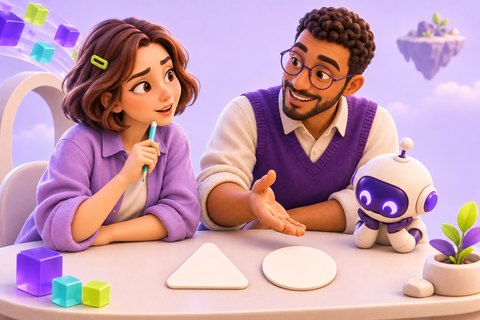

> **Мира:** Мы уже опубликовали сервис?

> **Данил:** Нет. Приложение работает как функция внутри ноутбука; публикация потребовала бы отдельного окружения и проверок.

> **Пикс:** Дальше отправим запрос через WSGI-контракт, не открывая порт.

<a id="step-3"></a>

## 3. Проверим успешный ответ и отказы

Соберём WSGI-окружение в памяти. Проверим сам JSON, заголовок длины и разные ошибки — не только существование функции.

In [4]:
def request(payload, path='/predict', method='POST'):
    body = json.dumps(payload).encode('utf-8')
    environ = {}
    setup_testing_defaults(environ)
    environ.update(PATH_INFO=path, REQUEST_METHOD=method, CONTENT_LENGTH=str(len(body)))
    environ['wsgi.input'] = io.BytesIO(body)
    captured = {}
    def start_response(status, headers):
        captured.update(status=status, headers=dict(headers))
    response = b''.join(app(environ, start_response))
    assert int(captured['headers']['Content-Length']) == len(response)
    return captured['status'], json.loads(response)
status, answer = request({'pixels': one.tolist()})
assert status == '200 OK' and answer['label'] == 1
assert request({'pixels': zero.tolist()})[1]['label'] == 0
assert request({'pixels': [[0]]})[0].startswith('400')
assert request({'pixels': (one/255).tolist()})[0].startswith('400')
assert request({'pixels': one.tolist()}, path='/missing')[0].startswith('404')
assert request({'pixels': one.tolist()}, method='GET')[0].startswith('405')
print('Ответ:', status, answer)
print('Проверены: 0, 1, неверная форма, неверный тип, путь и метод.')


Ответ: 200 OK {'label': 1, 'method': 'nearest-template'}
Проверены: 0, 1, неверная форма, неверный тип, путь и метод.


**Что проверить:** Проверены успешные ответы и четыре разных отказа без сети.

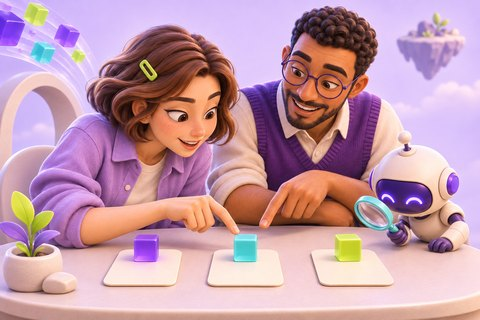

> **Мира:** Что ещё нужно перед настоящим запуском?

> **Данил:** Сохранение модели, ограничение нагрузки, окружение сервера и внешние проверки. Здесь проверен только локальный контракт.

> **Пикс:** 200 внутри ноутбука не означает опубликованный сайт.

<a id="your-experiment"></a>

## Попробуй сам

Отправь pixels с одним значением 300.

**Где изменить:** Создай копию one.tolist(), измени один элемент, вызови request.

**Как проверить:** Сервис вернёт 400: диапазон пикселей проверяется до классификации.

## Что теперь умеешь

- Обработка входа должна совпадать на всех путях.
- WSGI можно проверить в памяти без публикации.
- Код 200, качество модели и готовность к нагрузке — разные проверки.

## Границы этого примера

- Распознаются только два искусственных шаблона; это не универсальный распознаватель цифр.
- Сервис не опубликован; сеть, производительность и реальный сервер здесь не проверяются.

## Продолжить глубже

[Полная исходная работа в неизменяемом архиве](<https://github.com/safal207/students/blob/2e46691c24aabcb6e71852e07254a0965fc3a59b/%D0%A1%D0%BE%D0%B7%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BF%D1%80%D0%BE%D1%81%D1%82%D0%BE%D0%B3%D0%BE_%D0%B2%D0%B5%D0%B1_%D1%81%D0%B5%D1%80%D0%B2%D0%B5%D1%80%D0%B0_%D0%B8_%D0%BD%D0%B0%D1%81%D1%82%D1%80%D0%BE%D0%B9%D0%BA%D0%B0_%D0%BF%D0%B0%D1%80%D0%B0%D0%BC%D0%B5%D1%82%D1%80%D0%BE%D0%B2_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D1%8B.ipynb>). Она сохраняет большой эксперимент и его авторские материалы; её требования могут отличаться от этого короткого урока.

**Источники исходной работы:**

- [Источник 1](<https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%BE%D0%B7%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BF%D1%80%D0%BE%D1%81%D1%82%D0%BE%D0%B3%D0%BE_%D0%B2%D0%B5%D0%B1_%D1%81%D0%B5%D1%80%D0%B2%D0%B5%D1%80%D0%B0_%D0%B8_%D0%BD%D0%B0%D1%81%D1%82%D1%80%D0%BE%D0%B9%D0%BA%D0%B0_%D0%BF%D0%B0%D1%80%D0%B0%D0%BC%D0%B5%D1%82%D1%80%D0%BE%D0%B2_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D1%8B.ipynb>)

<details>
<summary>Что исправлено и упрощено в уроке</summary>

**Ошибка · исходная ячейка 20 (от 0).** Сервис делит пиксели на 255, тогда как обучающие массивы в ячейке 13 только меняют форму. → Одна prepare используется для эталонов и входа сервиса.

Проверка: prepare(one.tolist()) побитово совпадает с references[1].

Фрагмент исходника: <code>array=np.array(...)/255; обучение x_train.reshape(...)</code>

---

**Ограничение исходного примера · исходная ячейка 31 (от 0).** Исходный сценарий требует внешней учётной записи и секрета для развёртывания. → В основном уроке нет секретов, установки CLI и публикации; WSGI вызывается в памяти.

Проверка: Ответы и статусы проверяются request без сетевого соединения.

Фрагмент исходника: <code>Чтение HEROKU_API_KEY и последующий git push heroku</code>

---

**Ограничение исходного примера · исходная ячейка 18 (от 0).** x_test используется как validation во время обучения. → Качество обученной MNIST-модели не заявляется; две синтетические проверки оценивают контракт сервиса.

Проверка: Ответ содержит method=nearest-template, не обещание точности MNIST.

Фрагмент исходника: <code>validation_data=(x_test,y_test)</code>

</details>